<a href="https://colab.research.google.com/github/bauhaushm/TP-Delito_en_AMBA/blob/SantiagoPeralta/TP_Delito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal - Laboratorio de Métodos Cuantitativos
**Universidad de Buenos Aires - Facultad de Ciencias Económicas**  
**Tecnicatura Universitaria en Gestión y Análisis de Datos**  
**Segundo Cuatrimestre 2026**

---

### Integrantes del Grupo:
* **Chietino Luna, Micaela** - Registro: 921785 - Usuario GitHub: `@mchietino`
* **Iandoli, Franco** - Registro: 921507 - Usuario GitHub: `@Franco-Iandoli`
* **Ortiz, Naiara** - Registro: 921844 - Usuario GitHub: `@naiaraortizrodriguez`
* **Peralta, Santiago** - Registro: 921431 - Usuario GitHub: `@SantiagoNPeralta`
* **Turrillo, Bruno** - Registro: 921414 - Usuario GitHub: `@bauhaushm`

---

## 1. Introducción y Pregunta de Investigación

Nuestro grupo se focalizará en la temática del delito y su relación con aspectos sociales que pueden influir en él.

**a) Pregunta de investigación:**

> *"¿Cómo se comparan los patrones delictivos entre los partidos del AMBA, y de qué manera varían el tipo y la frecuencia de los delitos denunciados según las condiciones socioeconómicas y habitacionales al interior de las comunas porteñas?"*

**b) ¿Por qué vale la pena responderla?**
[Completar: qué decisión, fenómeno o problema ilumina. Por ejemplo, que el AMBA concentra gran parte de la población del país y que las políticas de seguridad requieren saber qué delitos predominan en cada territorio y si la brecha entre CABA y el conurbano se achica o se amplía.]

**c) ¿Qué respuesta encontramos?**
[Completar al finalizar el análisis, volviendo a esta celda con los hallazgos concretos.]

### 1.1 Fuente de datos

Utilizamos como fuente principal el Sistema Nacional de Información Criminal (SNIC), del Ministerio de Seguridad de la Nación. La base está disponible en https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos y contiene distintos datasets, de los cuales elegimos **"SNIC - Departamentos. Anual. Años 2000-2025"**.

Este dataset cubre todo el país, por lo que lo primero que hacemos es recortarlo al **Área Metropolitana de Buenos Aires (AMBA)**, que es el territorio que nos interesa para responder la pregunta de investigación.

## 2. Carga y exploración inicial de los datos

## 2.1 Importación de librerías

Importamos las librerías que vamos a usar: `pandas` para manipular los archivos, `matplotlib` y `seaborn` para los gráficos, `numpy` para operaciones matemáticas, `colorsys` para definir colores de las barras (convierte colores de HLS a RGB), y `requests` e `io` para descargar el archivo de forma controlada.


In [ ]:
import io
import colorsys
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Carga del dataset con fuente de respaldo y recorte al AMBA

En esta celda cargamos el dataset del SNIC con una función que prueba dos fuentes en orden:

1. **URL oficial del SNIC (Ministerio de Seguridad).** Es la fuente primaria, porque garantiza trabajar con la versión original y más actualizada de los datos.
2. **Copia del recorte ya filtrado (AMBA, 2017-2025) del mismo dataset, almacenada en el repositorio de GitHub del grupo.** Si la página oficial no responde (caída del sitio, error de red o tiempo de espera agotado), la función usa esta copia como respaldo.

Elegimos esta estructura por dos motivos. Primero, **reproducibilidad**: el notebook se ejecuta completo sin intervención manual, tanto en nuestras sesiones de Colab como cuando lo revise otra persona, aunque el servidor del SNIC esté temporalmente fuera de servicio. Segundo, **transparencia**: la función informa por pantalla de cuál de las dos fuentes se cargaron los datos, de modo que queda registro de qué versión se utilizó. Usamos la librería `requests` con un límite de tiempo (`timeout`) para evitar que la ejecución quede detenida indefinidamente esperando una respuesta.

Del archivo original pedimos solo seis columnas: "Año", "Provincia", "Departamento", "Tipo de delito", "Cantidad de hechos" y "Tasa de hechos" (cada 100.000 habitantes). Luego aplicamos dos filtros:

- **Período 2017-2025** (los últimos 9 años), para centrar el análisis en el escenario reciente y reducir el tamaño del dataset.
- **Territorio AMBA:** las 15 comunas de la Ciudad Autónoma de Buenos Aires y los 24 partidos del Gran Buenos Aires (conurbano bonaerense). Para evitar confundir partidos con nombres repetidos en otras provincias (como San Martín o Avellaneda), exigimos que coincidan a la vez la provincia y el departamento.

In [ ]:
# 1. Fuentes de datos
URL_SNIC = "https://cloud-snic.minseg.gob.ar/Bases/SNIC/snic-departamentos-anual.xlsx"
URL_REPO = "https://raw.githubusercontent.com/bauhaushm/TP-Delito_en_AMBA/bauhaushm/snic_amba_2017_2025.csv"
columnas = [0, 2, 4, 6, 7, 12]  # Año, Provincia, Departamento, Tipo de delito, Cantidad de hechos, Tasa

def cargar_snic():
    # Intento 1: URL oficial
    try:
        r = requests.get(URL_SNIC, timeout=30)
        r.raise_for_status()
        print("Datos cargados desde la URL oficial del SNIC.")
        return pd.read_excel(io.BytesIO(r.content), usecols=columnas)
    except Exception as e:
        print(f"No se pudo usar la URL oficial ({type(e).__name__}). Usando copia del repositorio...")
    # Intento 2: copia reducida (AMBA, 2017-2025) en el repositorio
    r = requests.get(URL_REPO, timeout=60)
    r.raise_for_status()
    print("Datos cargados desde la copia reducida en el repositorio de GitHub.")
    return pd.read_csv(io.BytesIO(r.content))

# 2. Cargar el dataset nacional
df = cargar_snic()

# 3. Definir el territorio AMBA
partidos_gba = ["Almirante Brown", "Avellaneda", "Berazategui", "Esteban Echeverría",
    "Ezeiza", "Florencio Varela", "General San Martín", "Hurlingham", "Ituzaingó",
    "José C. Paz", "La Matanza", "Lanús", "Lomas de Zamora", "Malvinas Argentinas",
    "Merlo", "Moreno", "Morón", "Quilmes", "San Fernando", "San Isidro", "San Miguel",
    "Tigre", "Tres de Febrero", "Vicente López"]

es_periodo = df["anio"].between(2017, 2025)
es_caba = df["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires"
es_conurbano = (df["provincia_nombre"] == "Buenos Aires") & (df["departamento_nombre"].isin(partidos_gba))

# 4. Filtrar período y territorio
df_amba = df[es_periodo & (es_caba | es_conurbano)].copy().reset_index(drop=True)

# 5. Verificar el resultado
print(f"El dataset del AMBA contiene {len(df_amba)} filas y {len(df_amba.columns)} columnas.")
print("Años incluidos:", sorted(df_amba["anio"].unique().tolist()))

# 6. Guardar el dataset resultante
df_amba.to_csv("snic_amba_2017_2025.csv", index=False)

Datos cargados desde la URL oficial del SNIC.
El dataset del AMBA contiene 21345 filas y 6 columnas.
Años incluidos: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


### 2.3 Primeras y últimas filas

Mostramos las primeras y últimas filas con `.head()` y `.tail()` para tener una primera impresión del contenido y confirmar que el orden y los valores tienen sentido.

In [ ]:
display(df_amba.head())
display(df_amba.tail())

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
0,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,9.870850
1,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,5.527676
2,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,75.018458
3,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
4,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,424.051707


,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
21340,2025,Buenos Aires,Vicente López,Lesiones dolosas,435,155.000641
21341,2025,Buenos Aires,Vicente López,Lesiones culposas en Accidentes Viales,681,242.656177
21342,2025,Buenos Aires,Vicente López,Lesiones culposas por otros hechos,13,4.632203
21343,2025,Buenos Aires,Vicente López,Otros delitos contra las personas,30,10.689699
21344,2025,Buenos Aires,Vicente López,Delitos contra el honor,0,0.000000


### 2.4 Estructura del dataset

Describimos las dimensiones, las columnas, sus tipos de dato (`.dtypes`) y la cobertura temporal y geográfica, para verificar que cada variable tenga el tipo adecuado (por ejemplo, el año como entero y la tasa como número decimal).

In [ ]:
print("Dimensiones (filas, columnas):", df_amba.shape)
print("\nColumnas y tipos de dato:")
print(df_amba.dtypes)
print("\nCobertura temporal:", df_amba["anio"].min(), "a", df_amba["anio"].max())
print("Comunas y partidos distintos:", df_amba["departamento_nombre"].nunique())
print("Tipos de delito distintos:", df_amba["codigo_delito_snic_nombre"].nunique())

Dimensiones (filas, columnas): (21345, 6)

Columnas y tipos de dato:
anio                           int64
provincia_nombre              object
departamento_nombre           object
codigo_delito_snic_nombre     object
cantidad_hechos                int64
tasa_hechos                  float64
dtype: object

Cobertura temporal: 2017 a 2025
Comunas y partidos distintos: 40
Tipos de delito distintos: 66


### 2.5 Calidad de los datos

Analizamos la presencia de valores nulos (`.isnull().sum()`), filas duplicadas y estadísticas descriptivas (`.describe()`). También calculamos qué proporción de las filas tiene cero hechos, porque en el SNIC un cero puede significar que no hubo casos, y eso condiciona cómo interpretamos las tasas y los promedios.

In [ ]:
print("Valores nulos por columna:")
print(df_amba.isnull().sum())
print("\nFilas duplicadas:", df_amba.duplicated().sum())
print(f"\nProporción de filas con cero hechos: {(df_amba['cantidad_hechos'] == 0).mean():.1%}")
df_amba.describe()

Valores nulos por columna:
anio                           0
provincia_nombre               0
departamento_nombre            0
codigo_delito_snic_nombre      0
cantidad_hechos                0
tasa_hechos                  534
dtype: int64

Filas duplicadas: 0

Proporción de filas con cero hechos: 42.2%


,anio,cantidad_hechos,tasa_hechos
count,21345.000000,21345.000000,20811.000000
mean,2021.170063,207.841368,67.360475
std,2.609329,736.560238,232.586402
min,2017.000000,0.000000,0.000000
25%,2019.000000,0.000000,0.000000
50%,2021.000000,3.000000,1.282462
75%,2023.000000,73.000000,22.706979
max,2025.000000,22881.000000,4053.030001


### 2.6 Diagnóstico de valores nulos en la tasa

Antes de decidir cómo tratar los nulos de `tasa_hechos`, analizamos cuántos hay en el AMBA y cómo se distribuyen por año, por comuna o partido y por cantidad de hechos.

In [ ]:
nulos_tasa = df_amba[df_amba["tasa_hechos"].isna()]
print(f"Nulos en tasa_hechos: {len(nulos_tasa)} ({len(nulos_tasa) / len(df_amba):.2%})")
print("\nPor año:")
print(nulos_tasa.groupby("anio").size())
print("\nPor comuna/partido (top 10):")
print(nulos_tasa.groupby("departamento_nombre").size().sort_values(ascending=False).head(10))
print("\nCantidad de hechos en las filas con tasa nula:")
print(nulos_tasa["cantidad_hechos"].describe())

Nulos en tasa_hechos: 534 (2.50%)

Por año:
anio
2017    56
2018    56
2019    56
2020    56
2021    56
2022    56
2023    66
2024    66
2025    66
dtype: int64

Por comuna/partido (top 10):
departamento_nombre
Departamento sin determinar    534
dtype: int64

Cantidad de hechos en las filas con tasa nula:
count      534.000000
mean       236.765918
std        811.529762
min          0.000000
25%          1.000000
50%          9.500000
75%         96.750000
max      10000.000000
Name: cantidad_hechos, dtype: float64


### 2.7 Exclusión de los hechos sin comuna asignada

Los registros con `departamento_nombre` igual a "Departamento sin determinar" corresponden a hechos que el SNIC no pudo atribuir a una comuna o partido. Representan todos los nulos de `tasa_hechos`, porque sin territorio no hay población de referencia para calcular la tasa. Como nuestra pregunta compara patrones entre comunas y partidos, estos registros no son utilizables. Antes de excluirlos, cuantificamos cuántos hechos representan para declarar el efecto como limitación.

In [ ]:
etiqueta = "Departamento sin determinar"
sd = df_amba[df_amba["departamento_nombre"] == etiqueta]

print("Provincia de origen de las filas sin determinar:")
print(sd["provincia_nombre"].value_counts())

hechos_sd = sd["cantidad_hechos"].sum()
hechos_amba = df_amba["cantidad_hechos"].sum()
caba = df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires"
hechos_caba = df_amba.loc[caba, "cantidad_hechos"].sum()

print(f"\nHechos sin comuna asignada: {hechos_sd:,.0f}")
print(f"Porcentaje del total AMBA: {hechos_sd / hechos_amba:.2%}")
print(f"Porcentaje del total de CABA: {hechos_sd / hechos_caba:.2%}")

Provincia de origen de las filas sin determinar:
provincia_nombre
Ciudad Autónoma de Buenos Aires    534
Name: count, dtype: int64

Hechos sin comuna asignada: 126,433
Porcentaje del total AMBA: 2.85%
Porcentaje del total de CABA: 7.08%


In [ ]:
df_amba = df_amba[df_amba["departamento_nombre"] != etiqueta].reset_index(drop=True)

print(f"Filas restantes: {len(df_amba)}")
print("Nulos en tasa_hechos:", df_amba["tasa_hechos"].isna().sum())
print("Nulos totales por columna:")
print(df_amba.isnull().sum())

Filas restantes: 20811
Nulos en tasa_hechos: 0
Nulos totales por columna:
anio                         0
provincia_nombre             0
departamento_nombre          0
codigo_delito_snic_nombre    0
cantidad_hechos              0
tasa_hechos                  0
dtype: int64


### 2.8 Verificación del recorte

Comprobamos que el filtro haya capturado las 15 comunas de CABA y los 24 partidos del conurbano. Si algún partido figura como faltante, es probable que el SNIC lo nombre distinto (abreviaturas, tildes, mayúsculas) y haya que ajustar la lista.

In [ ]:
dep_caba = sorted(df_amba.loc[df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires", "departamento_nombre"].unique())
dep_conurbano = sorted(df_amba.loc[df_amba["provincia_nombre"] == "Buenos Aires", "departamento_nombre"].unique())

print(f"Comunas de CABA encontradas: {len(dep_caba)} (esperadas: 15)")
print(f"Partidos del conurbano encontrados: {len(dep_conurbano)} (esperados: 24)")
print("Partidos faltantes:", sorted(set(partidos_gba) - set(dep_conurbano)))

Comunas de CABA encontradas: 15 (esperadas: 15)
Partidos del conurbano encontrados: 24 (esperados: 24)
Partidos faltantes: []


### 2.9 Diagnóstico de los tipos de delito

El SNIC pasa de 56 a 66 tipos de delito en 2023. Identificamos cuáles son los tipos nuevos y comprobamos que no existan categorías agregadas ("Total") que puedan inflar las sumas. Además comparamos los hechos de los tipos comunes y de los nuevos por año, para evaluar si el cambio de clasificación afecta la comparabilidad de la serie.

In [ ]:
tipos_por_anio = {a: set(g["codigo_delito_snic_nombre"]) for a, g in df_amba.groupby("anio")}
tipos_comunes = set.intersection(*tipos_por_anio.values())
tipos_nuevos = tipos_por_anio[2025] - tipos_comunes

print(f"Tipos presentes en todos los años: {len(tipos_comunes)}")
print(f"Tipos que aparecen desde 2023: {len(tipos_nuevos)}")
for t in sorted(tipos_nuevos):
    print("  -", t)

print("\nTipos que contienen 'total':", [t for t in df_amba['codigo_delito_snic_nombre'].unique() if "total" in t.lower()])

es_comun = df_amba["codigo_delito_snic_nombre"].isin(tipos_comunes)
resumen = pd.DataFrame({
    "hechos_tipos_comunes": df_amba[es_comun].groupby("anio")["cantidad_hechos"].sum(),
    "hechos_tipos_nuevos": df_amba[~es_comun].groupby("anio")["cantidad_hechos"].sum()
}).fillna(0)
resumen

Tipos presentes en todos los años: 56
Tipos que aparecen desde 2023: 10
  - Abuso sexual agravado
  - Abuso sexual simple
  - Acceso ilegal a sistemas informáticos y daños informáticos
  - Ciberdelitos sexuales vinculados a menores
  - Daños (no incluye informáticos)
  - Estafas y defraudaciones (no incluye virtuales) y usura
  - Estafas y defraudaciones asistidas virtualmente
  - Extorsiones
  - Secuestros extorsivos
  - Tentativa de abuso sexual con acceso carnal

Tipos que contienen 'total': []


,hechos_tipos_comunes,hechos_tipos_nuevos
anio,,
2017,414286,0.0
2018,430558,0.0
2019,518968,0.0
2020,401475,0.0
2021,472926,0.0
2022,494481,0.0
2023,477888,48327.0
2024,488345,61343.0
2025,455144,46200.0


### 2.10 Exclusión de los tipos de delito incorporados desde 2023

Para que la serie 2017-2025 sea comparable, nos quedamos solo con los 56 tipos de delito presentes en todos los años y excluimos los 10 que el SNIC incorporó en 2023. De lo contrario, los totales anuales mostrarían un aumento artificial a partir de ese año que reflejaría un cambio de clasificación y no un cambio real en el delito. Cuantificamos cuántos hechos se dejan afuera para declararlo como limitación.

In [ ]:
filas_antes = len(df_amba)
hechos_antes = df_amba["cantidad_hechos"].sum()

df_amba = df_amba[df_amba["codigo_delito_snic_nombre"].isin(tipos_comunes)].reset_index(drop=True)

hechos_despues = df_amba["cantidad_hechos"].sum()
print(f"Filas: {filas_antes} -> {len(df_amba)}")
print(f"Hechos excluidos: {hechos_antes - hechos_despues:,.0f} ({1 - hechos_despues / hechos_antes:.2%} del total 2017-2025)")
print("\nTipos de delito por año:")
print(df_amba.groupby("anio")["codigo_delito_snic_nombre"].nunique())

Filas: 20811 -> 19641
Hechos excluidos: 155,870 (3.62% del total 2017-2025)

Tipos de delito por año:
anio
2017    56
2018    56
2019    56
2020    56
2021    56
2022    56
2023    56
2024    56
2025    56
Name: codigo_delito_snic_nombre, dtype: int64


### 2.11 Visualización del dataframe del AMBA

Visualizamos el dataframe resultante. Cada fila representa la cantidad de hechos y la tasa por 100.000 habitantes de un tipo de delito, en una comuna o partido y un año determinados.

In [ ]:
df_amba

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
0,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,9.870850
1,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,5.527676
2,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,75.018458
3,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
4,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,424.051707
...,...,...,...,...,...,...
19636,2025,Buenos Aires,Vicente López,Lesiones dolosas,435,155.000641
19637,2025,Buenos Aires,Vicente López,Lesiones culposas en Accidentes Viales,681,242.656177
19638,2025,Buenos Aires,Vicente López,Lesiones culposas por otros hechos,13,4.632203
19639,2025,Buenos Aires,Vicente López,Otros delitos contra las personas,30,10.689699


### 2.12 Hallazgos de la exploración

- **Estructura:** el recorte del AMBA, para 2017-2025, tenía 21.345 filas y 6 columnas, con los tipos adecuados (año y cantidad de hechos como enteros, tasa como decimal). Tras la exclusión de los hechos sin comuna asignada y de los tipos de delito incorporados desde 2023, quedan [N] filas, correspondientes a 15 comunas de CABA y 24 partidos del conurbano.
- **Valores nulos:** el único nulo estaba en `tasa_hechos` (534 casos, 2,50%), todos en registros con "Departamento sin determinar", es decir, hechos que el SNIC no pudo atribuir a una comuna y para los que no existe población de referencia. Los excluimos, ya que no son utilizables para comparar territorios. Corresponden íntegramente a CABA y representan el 2,85% de los hechos del AMBA y el 7,08% de los de CABA, por lo que los totales de CABA quedan levemente subestimados y las comparaciones se hacen a nivel de comuna y partido. Tras la exclusión no quedan nulos en ninguna columna.
- **Cobertura de tipos de delito:** el SNIC pasa de 56 a 66 tipos desde 2023 (se incorporan, entre otros, ciberdelitos, extorsiones, secuestros extorsivos y estafas asistidas virtualmente). Esos 10 tipos nuevos representan entre el 9% y el 11% de los hechos de 2023-2025 y generarían un salto artificial en la serie temporal. Para garantizar la comparabilidad entre años, el análisis se restringe a los 56 tipos presentes en todo el período, lo que deja fuera el 3,6% de los hechos del total 2017-2025.
- **Duplicados:** no se encontraron filas duplicadas.
- **Ceros:** antes de las exclusiones, el 42,2% de las filas registraba cero hechos, ya que muchos tipos de delito son poco frecuentes en la mayoría de los territorios. Los conservamos, porque un cero informa que no hubo casos.
- **Estadísticos descriptivos:** antes de las exclusiones, la distribución de `tasa_hechos` era muy asimétrica: la mediana (alrededor de 1,3) era mucho menor que la media (alrededor de 67) y el máximo superaba las 4.000 cada 100.000 habitantes. Por eso priorizaremos totales agregados y comparaciones relativas, y no promedios simples entre tipos de delito.

## 3. Transformaciones y resumen estadístico

### 3.1 Creación de la variable `zona`

Para comparar CABA con el conurbano creamos una columna derivada `zona` que clasifica cada registro según su provincia. Esta variable es la base de todas las comparaciones que siguen.

In [ ]:
df_amba["zona"] = np.where(df_amba["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires", "CABA", "Conurbano")
df_amba["zona"].value_counts()

,count
zona,
Conurbano,12096
CABA,7545


### 3.2 Hechos delictivos totales por zona y año

Agrupamos por zona y año y sumamos la cantidad de hechos para ver el volumen de delitos registrado en CABA y en el conurbano y cómo evolucionó.

In [ ]:
hechos_zona_anio = df_amba.groupby(["anio", "zona"])["cantidad_hechos"].sum().unstack()
hechos_zona_anio

zona,CABA,Conurbano
anio,,
2017,176874,237412
2018,169763,260795
2019,195212,323756
2020,133138,268337
2021,172026,300900
2022,189465,305016
2023,183014,294874
2024,187558,300787
2025,177271,277873


**Interpretación:** el conurbano registra más hechos que CABA en todos los años del período, entre 1,3 y 2,0 veces más (1,3 en 2017, 2,0 en 2020 y 1,6 en 2025). Esto es esperable en parte por su mayor población, por lo que la comparación entre zonas se hace con la tasa (sección 3.3) y no con el volumen.

En la evolución, ambas zonas alcanzan su máximo en 2019 y caen en 2020 (CABA 32%, conurbano 17%), un descenso probablemente asociado a las restricciones a la circulación por la pandemia; la mayor caída de CABA amplía la brecha ese año. Desde 2021 las dos se recuperan y la relación conurbano/CABA se estabiliza en torno a 1,6. Entre 2017 y 2025 los hechos en CABA se mantienen prácticamente iguales (+0,2%), mientras que el conurbano crece 17%, aunque ese aumento se concentra hasta 2019 (+36% respecto de 2017) y luego se modera. En 2025 ambas zonas descienden respecto de 2024 (CABA 5,5%, conurbano 7,6%).

Cabe recordar que son hechos registrados, que dependen de las denuncias, y que los totales de CABA están subestimados un 7% por los hechos sin comuna asignada, lo que no altera el sentido de la comparación.

### 3.3 Tasa total de delitos por comuna y partido

Calculamos la tasa total de cada territorio sumando las tasas de todos los tipos de delito (son categorías excluyentes con la misma población de referencia) y promediándola entre 2017 y 2025. Esto permite ordenar a las 39 unidades por nivel de delito relativo a su población.

In [ ]:
tasa_total = (df_amba.groupby(["zona", "departamento_nombre", "anio"])["tasa_hechos"]
              .sum().reset_index(name="tasa_total"))
ranking = (tasa_total.groupby(["zona", "departamento_nombre"])["tasa_total"]
           .mean().sort_values(ascending=False).round(1))
ranking

zona       departamento_nombre
CABA       Comuna 1               10381.2
           Comuna 3                7499.8
           Comuna 4                6920.6
           Comuna 14               6154.8
           Comuna 9                5959.0
           Comuna 15               5526.9
           Comuna 7                5372.5
           Comuna 2                5266.4
           Comuna 8                4976.5
           Comuna 10               4797.1
           Comuna 5                4756.2
           Comuna 11               4371.7
           Comuna 13               4200.8
           Comuna 12               4082.1
           Comuna 6                4011.6
Conurbano  Morón                   3727.0
           General San Martín      3404.3
           Avellaneda              3315.0
           Ituzaingó               3241.4
           Tres de Febrero         3217.2
           Lanús                   2883.1
           Moreno                  2836.6
           San Isidro              2815.0
           Esteban Echeverría      2734.3
           Quilmes                 2731.3
           Malvinas Argentinas     2683.9
           José C. Paz             2681.1
           Tigre                   2635.2
           Berazategui             2619.6
           Hurlingham              2558.4
           Vicente López           2491.8
           San Miguel              2479.3
           Almirante Brown         2444.0
           Ezeiza                  2441.3
           San Fernando            2407.2
           Merlo                   2365.5
           Lomas de Zamora         2322.4
           La Matanza              2159.4
           Florencio Varela        2011.2
Name: tasa_total, dtype: float64

In [ ]:
print(ranking.head(5))
print(ranking.tail(5))
print("\nPromedio simple por zona:")
print(ranking.groupby("zona").mean().round(1))

zona  departamento_nombre
CABA  Comuna 1               10381.2
      Comuna 3                7499.8
      Comuna 4                6920.6
      Comuna 14               6154.8
      Comuna 9                5959.0
Name: tasa_total, dtype: float64
zona       departamento_nombre
Conurbano  San Fernando           2407.2
           Merlo                  2365.5
           Lomas de Zamora        2322.4
           La Matanza             2159.4
           Florencio Varela       2011.2
Name: tasa_total, dtype: float64

Promedio simple por zona:
zona
CABA         5618.5
Conurbano    2716.9
Name: tasa_total, dtype: float64


**Interpretación:** al ajustar por población, el panorama se invierte respecto del volumen: aunque el conurbano registra más hechos en total, las comunas de CABA tienen tasas sensiblemente más altas. El promedio simple de la tasa total anual es de unos 5.620 hechos cada 100.000 habitantes en CABA y de unos 2.720 en el conurbano, es decir, algo más del doble. La diferencia es sistemática: la comuna con menor tasa (Comuna 6, cerca de 4.010) supera al partido con mayor tasa (Morón, cerca de 3.730).

Dentro de cada zona también hay dispersión. En CABA encabezan el ranking las comunas 1, 3, 4, 14 y 9, con la Comuna 1 muy por encima del resto (más de 10.000, casi el doble del promedio de CABA). En el conurbano, los partidos con menores tasas son Florencio Varela, La Matanza, Lomas de Zamora, Merlo y San Fernando (entre 2.000 y 2.400), mientras que Morón, General San Martín y Avellaneda se ubican en el extremo alto de la zona. La brecha entre el territorio de mayor y menor tasa es de unas 2,6 veces en CABA y de unas 1,9 en el conurbano.

Estos resultados deben leerse con cautela. La tasa usa como denominador la población residente, por lo que tiende a sobreestimarse en comunas céntricas con mucha población flotante, como la Comuna 1. Además, se trata de delitos registrados, que dependen de la propensión a denunciar y esta puede diferir entre territorios. Por último, los promedios son simples (no ponderados por población). La fuerte heterogeneidad entre comunas justifica profundizar, en la segunda parte del trabajo, en la relación entre el delito y las condiciones socioeconómicas dentro de CABA.

## 4. Análisis gráfico

En esta sección representamos con gráficos los resultados anteriores, mirando el delito en el tiempo (2017-2025) y según la ubicación (las 15 comunas de CABA y los 24 partidos del conurbano). Usamos la tasa cada 100.000 habitantes del SNIC. Se trata de delitos denunciados, y desde 2022 el SNIC usa otra base de población, algo a tener en cuenta al comparar años.

### 4.1 Distribución y evolución temporal

#### 4.1.1 Serie principal: tasa total de delitos por zona

Evolución anual de la tasa de CABA y del conurbano. La franja gris marca 2020 (restricciones por la pandemia).

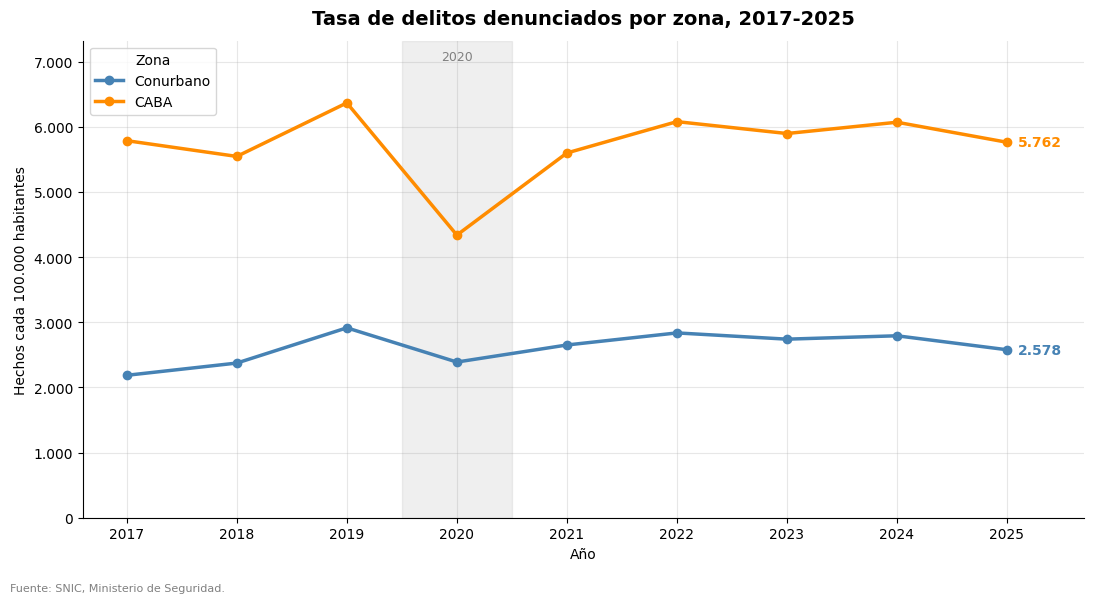

In [95]:
# Tasa total de delitos por zona y año: hechos de la zona / población de la zona * 100.000

# 1) Población de cada comuna/partido y año, despejada de la tasa del SNIC (hechos / tasa * 100.000)
k = df_amba[(df_amba["tasa_hechos"] > 0) & (df_amba["cantidad_hechos"] > 0)].copy()
k["pob"] = k["cantidad_hechos"] / k["tasa_hechos"] * 100000
pob = (k.groupby(["zona", "departamento_nombre", "anio"])["pob"].mean()   # una población por comuna/partido y año
         .groupby(["zona", "anio"]).sum())                                # se suman las comunas/partidos de cada zona

# 2) Hechos totales por zona y año
hechos_zona = df_amba.groupby(["zona", "anio"])["cantidad_hechos"].sum()

# 3) Tasa de cada zona
tasa_zona = (hechos_zona / pob * 100000).unstack(0)

# 4) Gráfico de líneas
fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(2019.5, 2020.5, color="gray", alpha=0.12)               # franja sombreada en 2020 (cuarentena)
ax.plot(tasa_zona.index, tasa_zona["Conurbano"], marker="o", linewidth=2.5, color="steelblue", label="Conurbano")
ax.plot(tasa_zona.index, tasa_zona["CABA"], marker="o", linewidth=2.5, color="darkorange", label="CABA")
for zona, color in [("Conurbano", "steelblue"), ("CABA", "darkorange")]:
    ax.annotate(f"{tasa_zona[zona].iloc[-1]:,.0f}".replace(",", "."), (tasa_zona.index[-1], tasa_zona[zona].iloc[-1]),
                textcoords="offset points", xytext=(8, 0), color=color, fontsize=10, fontweight="bold", va="center")
ax.set_title("Tasa de delitos denunciados por zona, 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Año")
ax.set_ylabel("Hechos cada 100.000 habitantes")
ax.set_xticks(tasa_zona.index)
ax.set_xlim(tasa_zona.index[0] - 0.4, tasa_zona.index[-1] + 0.7)  # deja lugar a la derecha para los valores de 2025
ax.set_ylim(0, tasa_zona.max().max() * 1.15)
ax.text(2020, ax.get_ylim()[1] * 0.98, "2020", ha="center", va="top", fontsize=9, color="gray")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))   # separador de miles con punto
ax.grid(axis="both", alpha=0.3)                                    # grilla horizontal y vertical, suave
ax.set_axisbelow(True)                                             # la grilla queda detrás de los datos
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Zona", loc="upper left")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("tasa_total_zonas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** la tasa de delitos registrados fue mayor en CABA que en el conurbano durante todo el período. En 2025 se registraron 5.762 hechos cada 100.000 habitantes en CABA, frente a 2.578 en el conurbano. En ambas zonas la tasa alcanzó un máximo en 2019, cayó en 2020 (a unos 4.340 en CABA y unos 2.390 en el conurbano) y se recuperó en los años siguientes.

Al comparar 2017 con 2025, la tasa de CABA se mantuvo prácticamente estable (−0,4 %), mientras que la del conurbano aumentó un 17,9 %, pasando de 2.186 a 2.578 hechos cada 100.000 habitantes. Esto muestra que la diferencia entre ambas zonas se redujo, aunque CABA sigue teniendo una tasa más del doble que la del conurbano. La caída de 2020 coincide con el año de las restricciones por la pandemia, aunque el gráfico por sí solo no permite determinar sus causas.

#### 4.1.2 Evolución de los principales tipos de delito

Muestra año por año la tasa de los cuatro delitos más frecuentes del AMBA (robos, hurtos, amenazas y lesiones dolosas), con un panel para cada zona, para ver qué delitos explican la evolución de la tasa total. Los dos paneles comparten la escala vertical, por lo que se pueden comparar directamente.

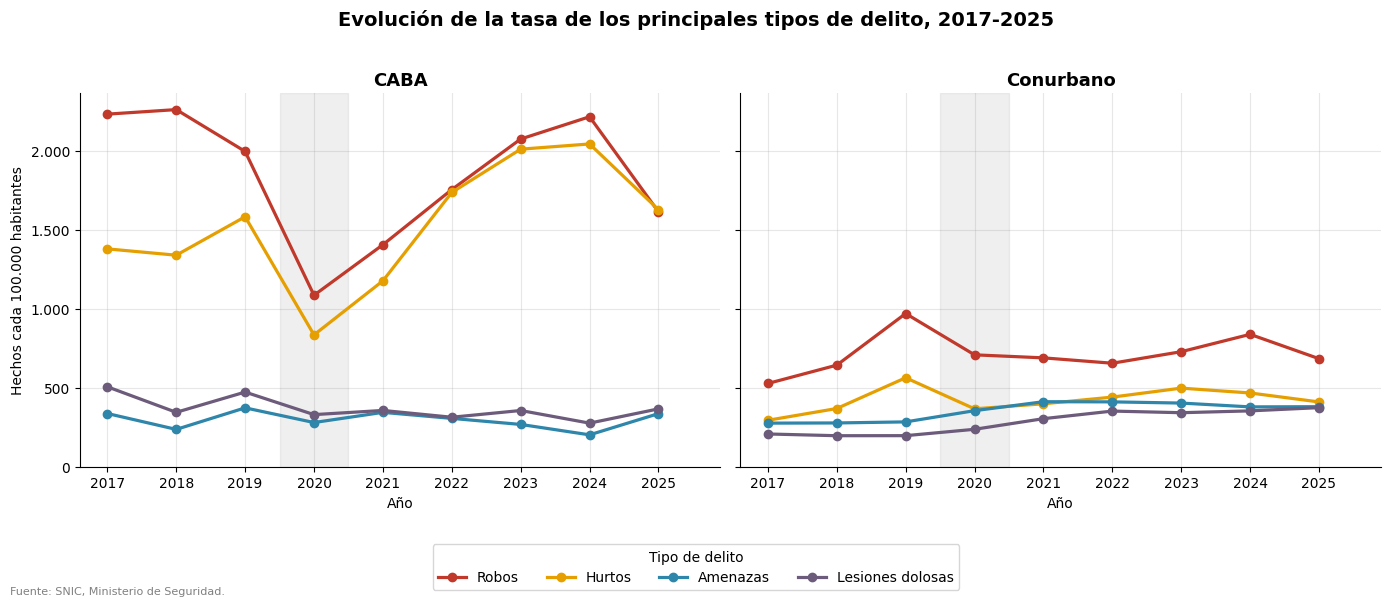

In [96]:
# Evolución anual de la tasa de los 4 tipos de delito más frecuentes del AMBA, por zona
# (tasa de la zona = hechos del tipo / población de la zona * 100.000; población despejada de la tasa del SNIC)

# 1) Población de cada zona y año, despejada de la tasa del SNIC (igual que en el gráfico 1)
k = df_amba[(df_amba["tasa_hechos"] > 0) & (df_amba["cantidad_hechos"] > 0)].copy()
k["pob"] = k["cantidad_hechos"] / k["tasa_hechos"] * 100000
pob = (k.groupby(["zona", "departamento_nombre", "anio"])["pob"].mean()   # una población por comuna/partido y año
         .groupby(["zona", "anio"]).sum())                                # se suman las comunas/partidos de cada zona

# 2) Tipos de delito a graficar: el nombre que se muestra y cómo empieza el nombre original en el SNIC
tipos_graf = {"Robos": "Robos (", "Hurtos": "Hurtos", "Amenazas": "Amenazas", "Lesiones dolosas": "Lesiones dolosas"}
colores_tipo = {"Robos": "#c0392b", "Hurtos": "#e69f00", "Amenazas": "#2e86ab", "Lesiones dolosas": "#6c5b7b"}

# 3) Un panel por zona; en cada uno, una línea por tipo de delito (hechos del tipo / población de la zona * 100.000)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)       # sharey: los dos paneles comparten la escala vertical
for ax, zona in zip(axes, ["CABA", "Conurbano"]):
    d = df_amba[df_amba["zona"] == zona]
    for nombre, inicio in tipos_graf.items():
        h = d[d["codigo_delito_snic_nombre"].str.startswith(inicio)].groupby("anio")["cantidad_hechos"].sum()
        serie = h / pob[zona] * 100000
        ax.plot(serie.index, serie.values, marker="o", linewidth=2.3, color=colores_tipo[nombre], label=nombre)
    ax.axvspan(2019.5, 2020.5, color="gray", alpha=0.12)           # franja sombreada en 2020 (cuarentena)
    ax.set_title(zona, fontsize=13, fontweight="bold")
    ax.set_xlabel("Año")
    ax.set_xticks(range(2017, 2026))
    ax.set_xlim(2016.6, 2025.9)
    ax.set_ylim(0, None)                                           # el eje vertical arranca en 0
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))   # separador de miles con punto
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="both", alpha=0.3)                                    # grilla horizontal y vertical, suave
    ax.set_axisbelow(True)                                             # la grilla queda detrás de los datos

# 4) Un solo título, una sola leyenda (abajo) y la fuente
axes[0].set_ylabel("Hechos cada 100.000 habitantes")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="Tipo de delito", loc="lower center", ncol=4, frameon=True, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Evolución de la tasa de los principales tipos de delito, 2017-2025", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.12, 1, 0.96])                          # deja lugar abajo para la leyenda
plt.savefig("evolucion_tipos_zonas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** el gráfico muestra que la evolución de la tasa total depende sobre todo de los robos y los hurtos. En CABA son los dos delitos con tasas más altas y los que más se mueven: el robo pasa de 2.232 en 2017 a 1.085 en 2020 (−51 %), se recupera hasta 2.215 en 2024 y baja a 1.613 en 2025. El hurto hace un recorrido parecido: 1.379 en 2017, 834 en 2020, 2.043 en 2024 y 1.627 en 2025. Amenazas y lesiones dolosas tienen tasas mucho más bajas y estables, entre 200 y 510.

En el conurbano el robo también es el delito con mayor tasa y alcanza su máximo en 2019 (970), pero después de la caída de 2020 no vuelve a ese nivel (684 en 2025). Las amenazas y las lesiones dolosas, en cambio, aumentan de forma sostenida: entre 2017 y 2025 las amenazas pasan de 276 a 380 y las lesiones dolosas de 207 a 374 (+81 %). En 2025, estos dos delitos y el hurto (410) quedan casi al mismo nivel. Entonces, en CABA la baja y la recuperación se explican por los delitos contra la propiedad, mientras que en el conurbano esos delitos se mantienen por debajo de 2019 y suben los delitos contra las personas.

#### 4.1.3 Distribución de la tasa por comuna y partido (boxplot)

Compara cómo se reparte la tasa promedio 2017-2025 entre las comunas de CABA y los partidos del conurbano. La caja contiene el 50 % central de las unidades, la línea negra es la mediana y los puntos fuera del bigote son valores atípicos.

           count     min     25%     50%     75%      max
zona                                                     
CABA        15.0  4012.0  4564.0  5266.0  6057.0  10381.0
Conurbano   24.0  2011.0  2443.0  2658.0  2848.0   3727.0


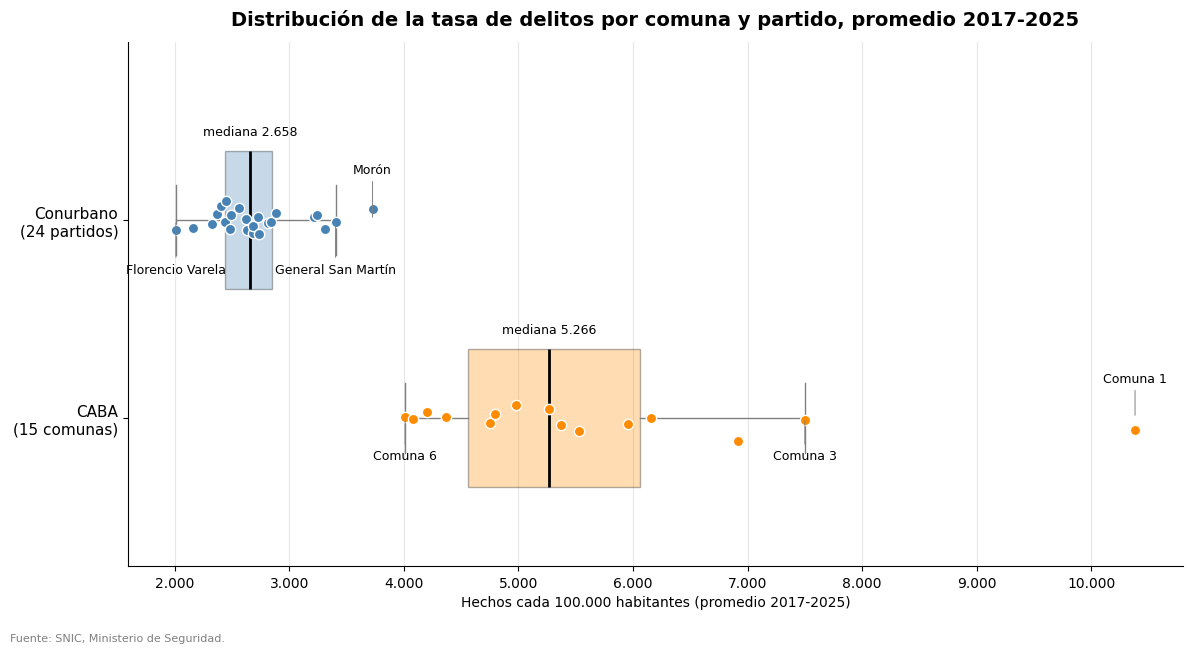

In [90]:
# Tasa total promedio 2017-2025 de cada comuna y de cada partido (una observación por unidad)
from matplotlib.ticker import MultipleLocator   # para marcar el eje cada 1.000


# 1) Tasa total por unidad y año: se suman las tasas de todos los tipos de delito de esa comuna o partido
tasa_unidad_anio = (
    df_amba
    .groupby(["zona", "departamento_nombre", "anio"], as_index=False)["tasa_hechos"]
    .sum()
)

# 2) Promedio de los nueve años para cada comuna o partido
tasa_unidad = tasa_unidad_anio.groupby(["zona", "departamento_nombre"])["tasa_hechos"].mean().reset_index()

# 3) Resumen estadístico por zona (para verificar lo que muestra el gráfico)
resumen = tasa_unidad.groupby("zona")["tasa_hechos"].describe()[["count", "min", "25%", "50%", "75%", "max"]].round(0)
print(resumen)

# 4) Boxplot horizontal: una caja por zona, con un punto por cada comuna o partido
orden = ["CABA", "Conurbano"]                     # CABA queda abajo y Conurbano arriba
colores = {"Conurbano": "steelblue", "CABA": "darkorange"}
alto_caja = {"CABA": 0.7, "Conurbano": 0.7}     # alto de cada caja (solo cambia el aspecto, no los datos)
etiquetas = {"CABA": "CABA\n(15 comunas)", "Conurbano": "Conurbano\n(24 partidos)"}
fig, ax = plt.subplots(figsize=(12, 6.5))
azar = np.random.default_rng(0)       # ruido vertical aleatorio, solo para que los puntos no se tapen entre sí
for pos, z in enumerate(orden):
    d = tasa_unidad[tasa_unidad["zona"] == z].sort_values("tasa_hechos")
    caja = ax.boxplot(d["tasa_hechos"], positions=[pos], vert=False, widths=alto_caja[z], patch_artist=True, showfliers=False,
                      medianprops=dict(color="black", linewidth=2), whiskerprops=dict(color="gray"), capprops=dict(color="gray"))
    caja["boxes"][0].set_facecolor(colores[z]); caja["boxes"][0].set_alpha(0.3)
    ax.scatter(d["tasa_hechos"], azar.normal(pos, 0.07 if z == "Conurbano" else 0.05, len(d)), color=colores[z], edgecolor="white", s=55, zorder=3)
    # Nombre del más bajo (debajo) y del más alto (arriba) de cada zona
    ax.annotate(d.iloc[0]["departamento_nombre"], (d.iloc[0]["tasa_hechos"], pos), xytext=(0, -30 if z == "CABA" else -38), textcoords="offset points",
                ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="gray", lw=0.7))
    ax.annotate(d.iloc[-1]["departamento_nombre"], (d.iloc[-1]["tasa_hechos"], pos), xytext=(0, 26 if z == "CABA" else 34), textcoords="offset points",
                ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="gray", lw=0.7))
    # Nombre del último valor dentro del bigote (el más alto que no es un valor atípico)
    q1, q3 = d["tasa_hechos"].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    ultimo = d[d["tasa_hechos"] <= limite].iloc[-1]
    ax.annotate(ultimo["departamento_nombre"], (ultimo["tasa_hechos"], pos), xytext=(0, -30 if z == "CABA" else -38), textcoords="offset points",
                ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="gray", lw=0.7))
    mediana = d["tasa_hechos"].median()
    ax.text(mediana, pos + alto_caja[z] / 2 + 0.08, "mediana " + f"{mediana:,.0f}".replace(",", "."), ha="center", fontsize=9)

ax.set_yticks(range(len(orden))); ax.set_yticklabels([etiquetas[z] for z in orden], fontsize=11)
ax.set_ylim(-0.75, 1.9)
ax.set_title("Distribución de la tasa de delitos por comuna y partido, promedio 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Hechos cada 100.000 habitantes (promedio 2017-2025)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.xaxis.set_major_locator(MultipleLocator(1000))      # una marca cada 1.000
ax.grid(axis="x", alpha=0.3)                           # líneas verticales suaves para leer los valores
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("distribucion_tasa_unidades.png", dpi=110)
plt.show()

**Interpretación:** el gráfico compara cómo se distribuye la tasa total promedio (2017-2025) entre las 15 comunas de CABA y los 24 partidos del conurbano. Las dos cajas casi no se superponen: la mediana de CABA es 5.266 hechos cada 100.000 habitantes y la del conurbano 2.658, es decir, cerca del doble. La comuna con menor tasa (Comuna 6, 4.012) está por encima del partido con mayor tasa (Morón, 3.727).

La dispersión es muy distinta entre zonas. En CABA el 50 % central de las comunas va de 4.564 a 6.057, un rango de unos 1.500 puntos, y los valores llegan hasta 7.500 (Comuna 3) dentro del bigote. En el conurbano el 50 % central va de 2.443 a 2.848, un rango de unos 400 puntos, y los partidos están mucho más agrupados, con extremos en Florencio Varela (2.011) y General San Martín.

Cada zona tiene un valor atípico, es decir, un punto que supera el límite del bigote (Q3 más 1,5 veces el largo de la caja): la Comuna 1, con 10.381 (límite de 8.296), y Morón, con 3.727 (límite de 3.456). En los dos casos son atípicos moderados, no extremos, aunque la Comuna 1 queda visualmente muy lejos del resto de CABA. Para interpretar su valor hay que recordar que la tasa se calcula con la población residente.

#### 4.1.4 Histograma de la tasa por comuna/partido y año

Muestra la misma comparación pero año por año, sin promediar el período: cada observación es una comuna o partido en un año. Las barras son el porcentaje de las observaciones de cada zona y las líneas punteadas, la mediana.

zona
Conurbano    216
CABA         135
Name: count, dtype: int64


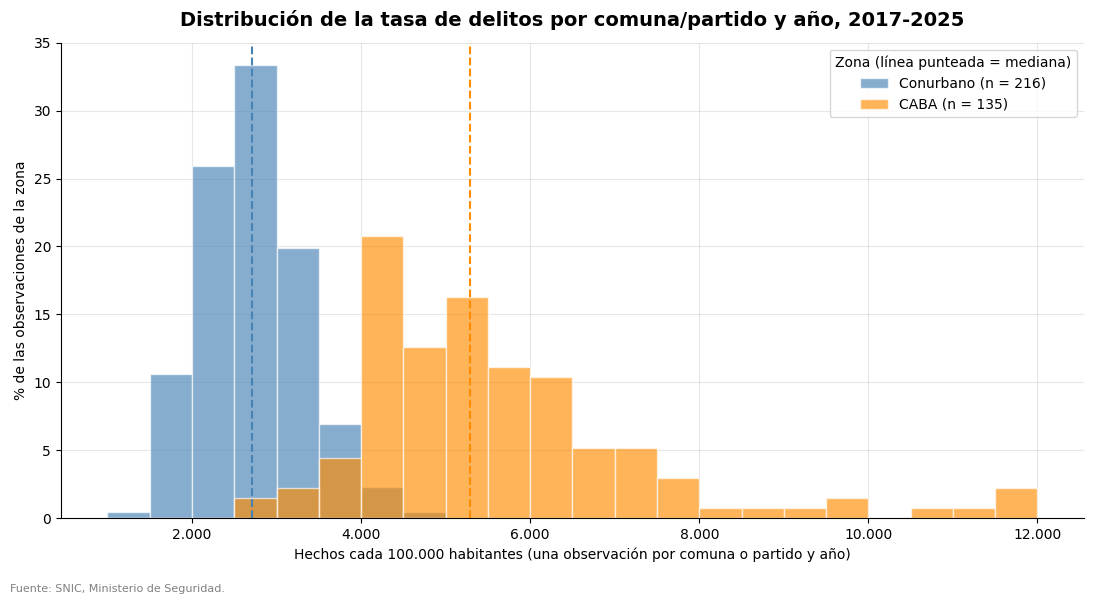

In [97]:
# Histograma de la tasa total de cada comuna y partido en cada año (una observación por unidad y año)

# 1) Tasa total por unidad y año (se suman las tasas de todos los tipos de delito)
tasa_unidad_anio = (
    df_amba
    .groupby(["zona", "departamento_nombre", "anio"], as_index=False)["tasa_hechos"]
    .sum()
)
# Control: 15 comunas x 9 años = 135 observaciones y 24 partidos x 9 años = 216
print(tasa_unidad_anio["zona"].value_counts())

# 2) Dos histogramas superpuestos, uno por zona, con los mismos intervalos
#    (cada barra muestra el % de las observaciones de su zona, porque hay distinta cantidad en cada una)
colores = {"Conurbano": "steelblue", "CABA": "darkorange"}
intervalos = np.arange(1000, 12500, 500)
fig, ax = plt.subplots(figsize=(11, 6))
for z in ["Conurbano", "CABA"]:
    valores = tasa_unidad_anio.loc[tasa_unidad_anio["zona"] == z, "tasa_hechos"]
    ax.hist(valores, bins=intervalos, weights=np.ones(len(valores)) / len(valores) * 100,
            color=colores[z], alpha=0.65, edgecolor="white", label=f"{z} (n = {len(valores)})")
    ax.axvline(valores.median(), color=colores[z], linestyle="--", linewidth=1.5)   # mediana de cada zona

ax.set_title("Distribución de la tasa de delitos por comuna/partido y año, 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Hechos cada 100.000 habitantes (una observación por comuna o partido y año)")
ax.set_ylabel("% de las observaciones de la zona")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Zona (línea punteada = mediana)", loc="upper right")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
ax.grid(axis="both", alpha=0.3)                                    # grilla horizontal y vertical, suave
ax.set_axisbelow(True)                                             # la grilla queda detrás de los datos
plt.savefig("histograma_tasa_unidades.png", dpi=110)
plt.show()

**Interpretación:** el histograma muestra la tasa total de cada comuna y partido en cada año (135 observaciones en CABA y 216 en el conurbano), expresada como porcentaje de las observaciones de su zona. Las dos distribuciones están claramente separadas.

El conurbano está muy concentrado: el 97 % de sus observaciones queda por debajo de 4.000 hechos cada 100.000 habitantes y su mediana es de unos 2.710. La barra más alta (entre 2.500 y 3.000) reúne alrededor de un tercio de las observaciones. CABA está desplazada hacia la derecha, con una mediana de unos 5.290, y es mucho más abierta: la barra más alta (entre 4.000 y 4.500) reúne solo un 21 % de las observaciones y hay una cola larga hacia valores altos. Hay 10 observaciones por encima de 8.000, ocho de la Comuna 1 y dos de la Comuna 3, y el máximo llega a unos 11.870.

Solo el 8 % de las observaciones de CABA queda por debajo de 4.000, por lo que las dos zonas casi no se superponen. Es coherente con el boxplot, pero acá se ve año por año y no solo el promedio de todo el período.

### 4.2 Comparación entre categorías

#### 4.2.1 Composición de los delitos por tipo

Muestra qué porcentaje de los hechos de cada zona corresponde a cada tipo de delito (los 12 más frecuentes y el resto agrupado), para ver qué delitos pesan más en CABA y cuáles en el conurbano. Cada zona suma 100 %, por lo que el gráfico compara la composición y no la cantidad: no dice en cuál de las dos zonas hay más delito.

Suma de porcentajes por zona:
zona
CABA         100.0
Conurbano    100.0
dtype: float64


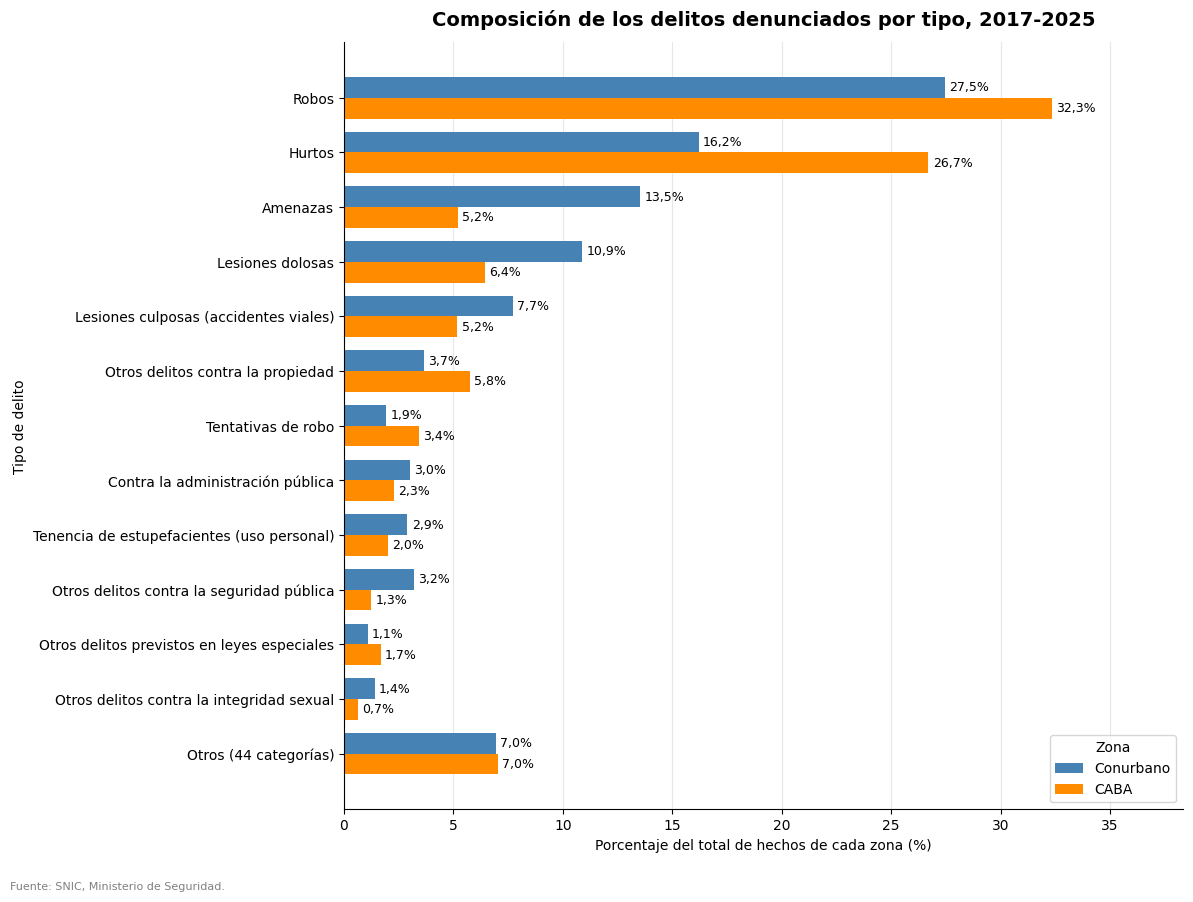

In [84]:
# 1) Nombres cortos para los tipos de delito más largos (así entran en el gráfico)
nombres_cortos = {
    "Robos (excluye los agravados por el resultado de lesiones y/o muertes)": "Robos",
    "Lesiones culposas en Accidentes Viales": "Lesiones culposas (accidentes viales)",
    "Tentativas de robo (excluye las agravadas por el res. de lesiones y/o muerte)": "Tentativas de robo",
    "Delitos contra la administración pública": "Contra la administración pública",
    "Tenencia simple atenuada para uso personal de estupefacientes": "Tenencia de estupefacientes (uso personal)",
}
# Si el tipo está en el diccionario se usa el nombre corto; si no, se deja el nombre original
df_amba["tipo"] = df_amba["codigo_delito_snic_nombre"].map(nombres_cortos).fillna(df_amba["codigo_delito_snic_nombre"])

# 2) Hechos por tipo de delito y zona (una fila por tipo, una columna por zona)
hechos = df_amba.groupby(["zona", "tipo"])["cantidad_hechos"].sum().unstack(0).fillna(0)

# 3) Porcentaje de cada tipo sobre el total de hechos de su zona
pct = hechos / hechos.sum() * 100

# 4) Nos quedamos con los 12 tipos con mayor suma de porcentajes (entre las dos zonas) y juntamos el resto en una sola fila
top = pct.sum(axis=1).sort_values(ascending=False).head(12).index
tabla_tipos = pct.loc[top]
nombre_otros = f"Otros ({len(pct) - 12} categorías)"          # cuántas categorías se agrupan
tabla_tipos.loc[nombre_otros] = 100 - tabla_tipos.sum()
tabla_tipos = tabla_tipos.iloc[::-1]          # se invierte el orden para que el más frecuente quede arriba
# Control: los porcentajes de cada zona tienen que sumar 100
print("Suma de porcentajes por zona:")
print(tabla_tipos.sum().round(1))

# 5) Gráfico de barras agrupadas: una barra por zona para cada tipo de delito
y = np.arange(len(tabla_tipos))               # posición de cada tipo en el eje vertical
alto = 0.38                                   # alto de cada barra
fig, ax = plt.subplots(figsize=(12, 9))
b1 = ax.barh(y + alto/2, tabla_tipos["Conurbano"], alto, label="Conurbano", color="steelblue")
b2 = ax.barh(y - alto/2, tabla_tipos["CABA"], alto, label="CABA", color="darkorange")
for barras, zona in [(b1, "Conurbano"), (b2, "CABA")]:
    ax.bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in tabla_tipos[zona]], padding=3, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(tabla_tipos.index)
ax.set_title("Composición de los delitos denunciados por tipo, 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Porcentaje del total de hechos de cada zona (%)")
ax.set_ylabel("Tipo de delito")
ax.set_xlim(0, tabla_tipos.max().max() + 6)  # deja lugar a la derecha para las etiquetas
ax.grid(axis="x", alpha=0.3)                                       # grilla solo vertical
ax.set_axisbelow(True)                                             # la grilla queda detrás de los datos
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Zona", loc="lower right")
fig.text(0.01, 0.005, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("tipos_delito.png", dpi=110)
plt.show()

**Interpretación:** el gráfico muestra qué porcentaje del total de hechos de cada zona corresponde a cada tipo de delito. En las dos zonas los robos y los hurtos son los más frecuentes, pero pesan más en CABA: suman el 59 % de los hechos (32,3 % y 26,7 %), contra el 43,7 % en el conurbano (27,5 % y 16,2 %). También pesan más en CABA otros delitos contra la propiedad (5,8 % contra 3,7 %) y las tentativas de robo (3,4 % contra 1,9 %).

En el conurbano tienen más peso los delitos contra las personas y la seguridad pública: amenazas (13,5 % contra 5,2 % en CABA), lesiones dolosas (10,9 % contra 6,4 %), lesiones culposas por accidentes viales (7,7 % contra 5,2 %), otros delitos contra la seguridad pública (3,2 % contra 1,3 %) y tenencia de estupefacientes para uso personal (2,9 % contra 2,0 %). Las 44 categorías restantes suman el 7,0 % en las dos zonas.

Son porcentajes del total de cada zona, no tasas: que un tipo pese menos en una zona no significa que haya menos casos de ese delito.

#### 4.2.2 Variación de la tasa 2017-2025 por comuna de CABA

Cambio porcentual de la tasa de cada comuna entre 2017 y 2025, ordenado de menor a mayor. Verde indica una baja y rojo un aumento.

Comunas incluidas: 15


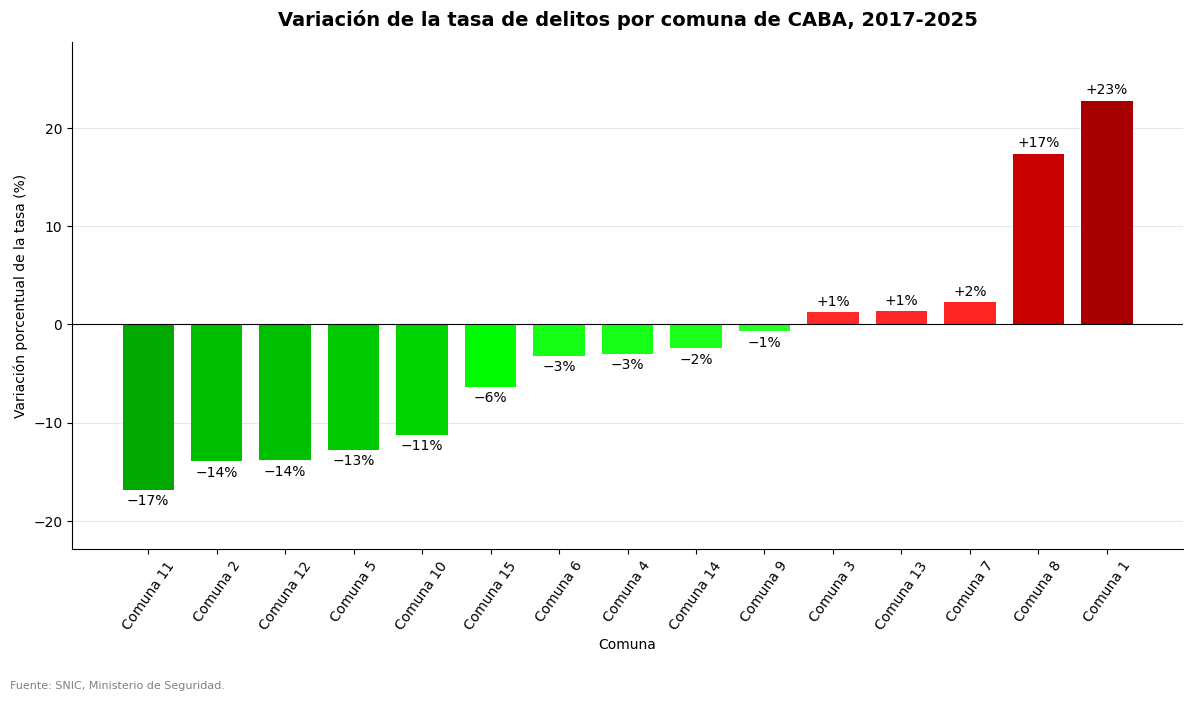

In [85]:
# Variación 2017-2025 de la tasa total de cada comuna: se suman las tasas de todos los tipos de delito
# de cada año (dentro de una misma unidad comparten la población) y se compara 2025 con 2017.

# 1) Tasa total por comuna y año, y tabla con una fila por comuna y una columna por año
tasa_anio = (
    df_amba[df_amba["zona"] == "CABA"]
    .groupby(["anio", "departamento_nombre"], as_index=False)["tasa_hechos"]
    .sum()
)
tabla = tasa_anio.pivot(index="departamento_nombre", columns="anio", values="tasa_hechos")
print("Comunas incluidas:", len(tabla))                      # control: tienen que ser 15

# 2) Variación porcentual entre 2017 y 2025, ordenada de menor a mayor (forma de escalera)
variacion = ((tabla[2025] / tabla[2017]) - 1) * 100
variacion = variacion.sort_values()

# 3) Colores: rojo si la tasa subió, verde si bajó (cuanto mayor la variación, más oscuro el tono)
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)

pos = variacion[variacion > 0].abs()    # donde la tasa subió
neg = variacion[variacion < 0].abs()    # donde la tasa bajó

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0
    else color(v, 1/3, neg.min(), neg.max())
    for v in variacion
]

# 4) Gráfico de barras
fig, ax = plt.subplots(figsize=(12, 7))
barras = ax.bar(variacion.index, variacion.values, color=colores, width=0.75)
ax.bar_label(barras, labels=[f"{v:+.0f}%".replace("-", "−") for v in variacion], padding=3, fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)                                   # línea del cero
ax.set_title("Variación de la tasa de delitos por comuna de CABA, 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Comuna")
ax.set_ylabel("Variación porcentual de la tasa (%)")
ax.set_xticks(range(len(variacion)))
ax.set_xticklabels(variacion.index, rotation=55, ha="center")
ax.grid(axis="y", alpha=0.3)                                       # grilla solo horizontal
ax.set_axisbelow(True)                                             # la grilla queda detrás de los datos
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(variacion.min() - 6, variacion.max() + 6)              # margen para las etiquetas
fig.text(0.01, 0.008, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("variacion_caba_escalera.png", dpi=110)
plt.show()

**Interpretación:** el gráfico muestra cuánto cambió la tasa total de cada comuna de CABA entre 2017 y 2025. Aunque la tasa de CABA en conjunto casi no varió, las comunas tuvieron recorridos distintos: 10 de las 15 bajaron y 5 subieron.

Las mayores bajas fueron las de la Comuna 11 (−17 %), las comunas 2 y 12 (−14 %), la 5 (−13 %) y la 10 (−11 %). Otras cinco bajaron menos, entre −6 % y −1 %. Entre las que subieron, las comunas 3, 13 y 7 casi no cambiaron (entre +1 % y +2 %), mientras que la 8 (+17 %) y la 1 (+23 %) tuvieron aumentos claros.

La Comuna 1 es la que más sube y además ya tenía la tasa más alta en 2017, por lo que la distancia con el resto de las comunas aumenta. Son comparaciones entre dos años, por lo que no muestran lo que pasó entre medio.

#### 4.2.3 Variación de la tasa 2017-2025 por partido del conurbano

Mismo gráfico para los 24 partidos del conurbano.

Partidos incluidos: 24


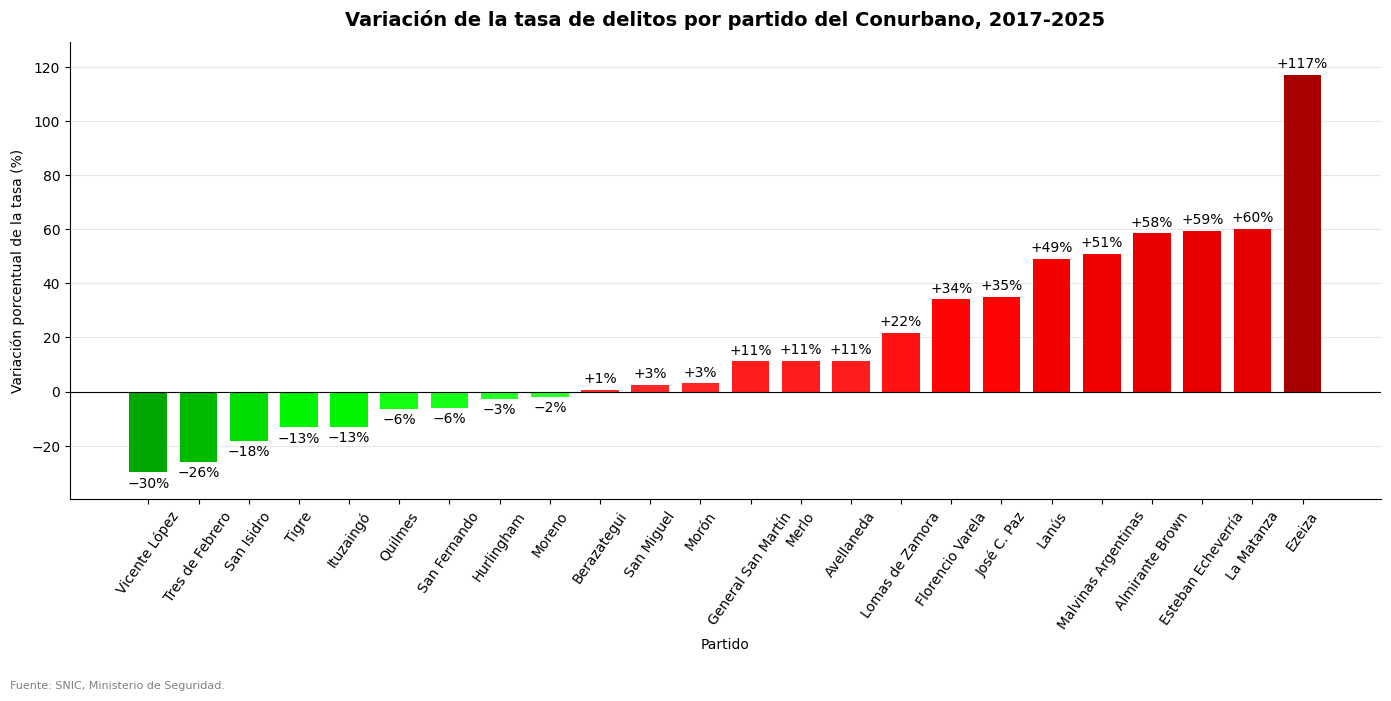

In [87]:
# Variación 2017-2025 de la tasa total de cada partido: se suman las tasas de todos los tipos de delito
# de cada año (dentro de una misma unidad comparten la población) y se compara 2025 con 2017.

# 1) Tasa total por partido y año, y tabla con una fila por partido y una columna por año
tasa_anio = (
    df_amba[df_amba["zona"] == "Conurbano"]
    .groupby(["anio", "departamento_nombre"], as_index=False)["tasa_hechos"]
    .sum()
)
tabla = tasa_anio.pivot(index="departamento_nombre", columns="anio", values="tasa_hechos")
print("Partidos incluidos:", len(tabla))                      # control: tienen que ser 24

# 2) Variación porcentual entre 2017 y 2025, ordenada de menor a mayor (forma de escalera)
variacion = ((tabla[2025] / tabla[2017]) - 1) * 100
variacion = variacion.sort_values()

# 3) Colores: rojo si la tasa subió, verde si bajó (cuanto mayor la variación, más oscuro el tono)
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)

pos = variacion[variacion > 0].abs()    # donde la tasa subió
neg = variacion[variacion < 0].abs()    # donde la tasa bajó

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0
    else color(v, 1/3, neg.min(), neg.max())
    for v in variacion
]

# 4) Gráfico de barras
fig, ax = plt.subplots(figsize=(14, 7))
barras = ax.bar(variacion.index, variacion.values, color=colores, width=0.75)
ax.bar_label(barras, labels=[f"{v:+.0f}%".replace("-", "−") for v in variacion], padding=3, fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)                                   # línea del cero
ax.set_title("Variación de la tasa de delitos por partido del Conurbano, 2017-2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Partido")
ax.set_ylabel("Variación porcentual de la tasa (%)")
ax.set_xticks(range(len(variacion)))
ax.set_xticklabels(variacion.index, rotation=55, ha="center")
ax.grid(axis="y", alpha=0.3)                                       # grilla solo horizontal
ax.set_axisbelow(True)                                             # la grilla queda detrás de las barras
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(variacion.min() - 10, variacion.max() + 12)              # margen para las etiquetas
fig.text(0.01, 0.008, "Fuente: SNIC, Ministerio de Seguridad.", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("variacion_conurbano_escalera.png", dpi=110)
plt.show()

**Interpretación:** el gráfico muestra cuánto cambió la tasa total de cada partido del conurbano entre 2017 y 2025. En esta zona predominan los aumentos: 15 de los 24 partidos subieron y 9 bajaron, y las variaciones son mucho mayores que en CABA.

Los mayores aumentos fueron los de Ezeiza (+117 %), La Matanza (+60 %), Esteban Echeverría (+59 %), Almirante Brown (+58 %), Malvinas Argentinas (+51 %) y Lanús (+49 %). Otros seis partidos subieron de forma moderada, entre +11 % y +35 % (General San Martín, Merlo y Avellaneda con +11 %, Lomas de Zamora con +22 %, Florencio Varela con +34 % y José C. Paz con +35 %). Tres casi no cambiaron: Berazategui (+1 %), San Miguel y Morón (+3 %).

Entre los 9 partidos que bajaron, las mayores caídas fueron las de Vicente López (−30 %), Tres de Febrero (−26 %) y San Isidro (−18 %). Tigre e Ituzaingó bajaron un 13 %, Quilmes y San Fernando un 6 %, y Hurlingham y Moreno entre un 2 % y un 3 %.

Son comparaciones entre dos años, por lo que no muestran lo que pasó entre medio. Además hay que tomar con cuidado los aumentos de La Matanza y de otros partidos grandes: el SNIC cambió la población de referencia en 2022 (La Matanza pasó de unos 2,3 a 1,8 millones), y eso hace subir la tasa aunque la cantidad de hechos no cambie. Por eso, los porcentajes de este gráfico conviene tomarlos como una referencia del cambio y no como una medida exacta de cuánto aumentó o bajó el delito en cada partido.